In [1]:
import pandas as pd
df = pd.read_csv("train.csv")

print(df.shape)
print(df.head())

(1460, 81)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008  

In [2]:
X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1460, 80)
y shape: (1460,)


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1168, 80)
X_test: (292, 80)
y_train: (1168,)
y_test: (292,)


In [4]:
numeric_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

print("\nNumeric:")
print(numeric_cols)

print("\nCategorical:")
print(categorical_cols)

Numeric columns: 37
Categorical columns: 43

Numeric:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

Categorical:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Function

C:\Users\soura\AppData\Local\Temp\ipykernel_16236\1051552230.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


In [5]:
#Drop ID column
X_train = X_train.drop("Id", axis=1)
X_test = X_test.drop("Id", axis=1)

print(X_train.shape)
print(X_test.shape)

(1168, 79)
(292, 79)


In [6]:
#Check number of numeric and categorical columns after dropping ID column
numeric_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric:", len(numeric_cols))
print("Categorical:", len(categorical_cols))

Numeric: 36
Categorical: 43


C:\Users\soura\AppData\Local\Temp\ipykernel_16236\2130439149.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


In [7]:
#Numeric pipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [8]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [9]:
#Create column Transformer
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

In [10]:
#transform the data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed:", X_train_processed.shape)
print("X_test_processed:", X_test_processed.shape)

X_train_processed: (1168, 285)
X_test_processed: (292, 285)


In [11]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

model = Sequential([
    Input(shape=(285,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(1, activation="linear")
])

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        36,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,929 (175.50 KB)

 Trainable params: 44,929 (175.50 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [14]:
history = model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - loss: 39143301120.0000 - mae: 181516.9688 - val_loss: 37831065600.0000 - val_mae: 181073.0938
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 39115321344.0000 - mae: 181445.5000 - val_loss: 37775351808.0000 - val_mae: 180927.7500
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 39012450304.0000 - mae: 181180.4219 - val_loss: 37609193472.0000 - val_mae: 180492.7656
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 38760710144.0000 - mae: 180527.2969 - val_loss: 37249785856.0000 - val_mae: 179549.6719
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 38265860096.0000 - mae: 179236.7500 - val_loss: 36594982912.0000 - val_mae: 177821.1094
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 37421531136.0000 - mae: 177034.2656 - val_loss: 35556950016.0000 - val_mae: 175046.0781
Epoch 7/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 36151230464.0000 - mae: 173650.7656 - val_loss: 34051977216

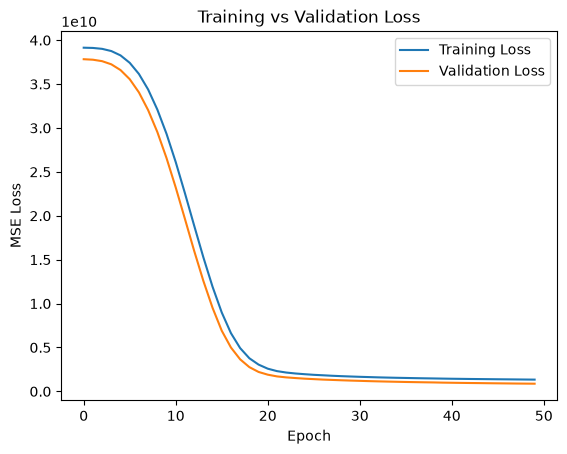

In [15]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

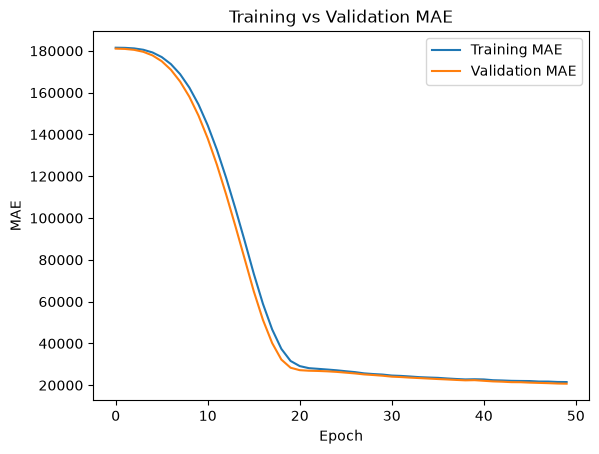

In [16]:
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training vs Validation MAE")
plt.legend()
plt.show()

In [17]:
from tensorflow.keras.callbacks import EarlyStopping
#create early stopping callback
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [18]:
history_es = model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 1329754368.0000 - mae: 21389.7383 - val_loss: 862899648.0000 - val_mae: 20562.0176
Epoch 2/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 1320938880.0000 - mae: 21290.0000 - val_loss: 852982912.0000 - val_mae: 20522.1777
Epoch 3/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 1312829440.0000 - mae: 21192.3691 - val_loss: 841478080.0000 - val_mae: 20326.2891
Epoch 4/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 1303979136.0000 - mae: 20965.4004 - val_loss: 833164160.0000 - val_mae: 20154.2305
Epoch 5/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 1293851904.0000 - mae: 20930.2090 - val_loss: 824246592.0000 - val_mae: 20075.5312
Epoch 6/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 1286007552.0000 - mae: 20874.9941 - val_loss: 815476992.0000 - val_mae: 20004.8008
Epoch 7/200
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 1279171200.0000 - mae: 20658.7148 - val_loss: 807849408.0000 - val_mae: 19814.1367

In [19]:
print("Epochs completed:", len(history_es.history["loss"]))

Epochs completed: 197


In [20]:
best_epoch = history_es.history["val_loss"].index(
    min(history_es.history["val_loss"])
) + 1

print("Best epoch:", best_epoch)
print("Best validation loss:", min(history_es.history["val_loss"]))

Best epoch: 192
Best validation loss: 453402720.0


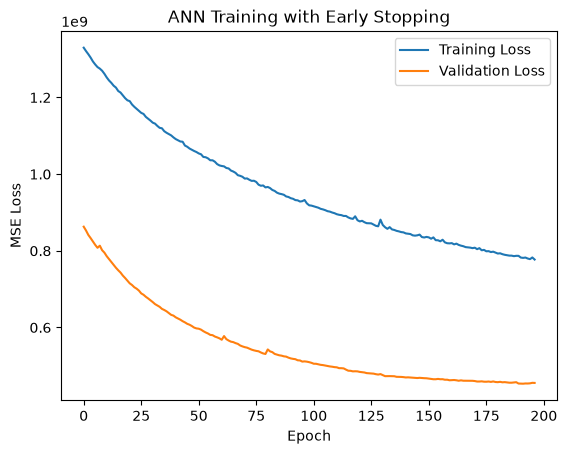

In [21]:
plt.plot(history_es.history["loss"], label="Training Loss")
plt.plot(history_es.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("ANN Training with Early Stopping")
plt.legend()
plt.show()

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_test_pred = model.predict(X_test_processed).flatten()

mae = mean_absolute_error(y_test, y_test_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
r2 = r2_score(y_test, y_test_pred)

print("ANN Test MAE :", mae)
print("ANN Test RMSE:", rmse)
print("ANN Test R²  :", r2)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
ANN Test MAE : 18904.865234375
ANN Test RMSE: 31409.46099505689
ANN Test R²  : 0.8713803887367249


In [23]:
#tuning the learning rate
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

def create_model(learning_rate):

    model = Sequential([
        Input(shape=(285,)),
        Dense(128, activation="relu"),
        Dense(64, activation="relu"),
        Dense(1, activation="linear")
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="mse",
        metrics=["mae"]
    )

    return model    

In [24]:
learning_rates = [0.0001, 0.001, 0.01]

results = []

for lr in learning_rates:

    model = create_model(lr)

    history = model.fit(
        X_train_processed,
        y_train,
        validation_split=0.2,
        epochs=50,
        batch_size=32,
        verbose=0
    )

    y_pred = model.predict(X_test_processed, verbose=0).flatten()

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append([lr, mae, rmse, r2])

print(results)

[[0.0001, 174252.75, np.float64(194668.7380346418), -3.9405875205993652], [0.001, 22162.439453125, np.float64(39244.20038680875), 0.7992122769355774], [0.01, 18243.5234375, np.float64(29969.404131547228), 0.8829039335250854]]


In [25]:
#tuning the number of layers and neurons
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

def create_ann(layers):

    model = Sequential()
    model.add(Input(shape=(285,)))

    for neurons in layers:
        model.add(Dense(neurons, activation="relu"))

    model.add(Dense(1, activation="linear"))

    model.compile(
        optimizer=Adam(learning_rate=0.01),
        loss="mse",
        metrics=["mae"]
    )

    return model

In [ ]:
architectures = [
    [64, 32],
    [128, 64],
    [256, 128, 64]
]

architecture_results = []

for architecture in architectures:

    model = create_ann(architecture)

    model.fit(
        X_train_processed,
        y_train, 
        validation_split=0.2,
        epochs=50,
        batch_size=32,
        verbose=0
    )

    y_pred = model.predict(
        X_test_processed,
        verbose=0
    ).flatten()

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    architecture_results.append([
        architecture,
        mae,
        rmse,
        r2
    ])

for result in architecture_results:
    print(result)

[[64, 32], 18353.271484375, np.float64(30420.77921421475), 0.8793501257896423]
[[128, 64], 19469.8828125, np.float64(30651.774239022445), 0.8775109052658081]
[[256, 128, 64], 17648.078125, np.float64(29668.79680742042), 0.8852412104606628]


In [27]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam

model_dropout = Sequential([
    Input(shape=(285,)),

    Dense(256, activation="relu"),
    Dropout(0.2),

    Dense(128, activation="relu"),
    Dropout(0.2),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="linear")
])

model_dropout.compile(
    optimizer=Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

In [28]:
history_dropout = model_dropout.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - loss: 29663928320.0000 - mae: 149552.0781 - val_loss: 3005828864.0000 - val_mae: 48337.7578
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 3625136128.0000 - mae: 43706.7969 - val_loss: 1165782784.0000 - val_mae: 27322.0508
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 2227854848.0000 - mae: 31013.2617 - val_loss: 855954112.0000 - val_mae: 19216.9414
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 1919872384.0000 - mae: 27108.4434 - val_loss: 714634304.0000 - val_mae: 17535.4258
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 1741938432.0000 - mae: 27557.5059 - val_loss: 582052800.0000 - val_mae: 16356.4590
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 1521634688.0000 - mae: 25213.4922 - val_loss: 567614464.0000 - val_mae: 15858.9561
Epoch 7/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 1531401600.0000 - mae: 26119.9121 - val_loss: 972791936.0000 - val_mae: 22242.6504
Ep

In [29]:
y_pred_dropout = model_dropout.predict(
    X_test_processed,
    verbose=0
).flatten()

mae_dropout = mean_absolute_error(y_test, y_pred_dropout)
rmse_dropout = np.sqrt(mean_squared_error(y_test, y_pred_dropout))
r2_dropout = r2_score(y_test, y_pred_dropout)

print("Dropout ANN Test MAE :", mae_dropout)
print("Dropout ANN Test RMSE:", rmse_dropout)
print("Dropout ANN Test R²  :", r2_dropout)

Dropout ANN Test MAE : 18483.390625
Dropout ANN Test RMSE: 29026.159787336663
Dropout ANN Test R²  : 0.8901587724685669
